In [1]:

import pandas as pd

df = pd.read_csv("Retail_outlets.csv")

df.head()


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1079,East,Town,5053.285500,945.839116,8264.861349,309.758037,26.886747,77.678159,97.759093,2.045180,48358.887458,Autumn,37269.08
1,1009,South,Town,5932.964720,1522.784544,10715.078680,500.225154,38.668926,67.495612,89.531440,4.137114,50390.304228,Spring,51422.51
2,1063,East,Mall,4835.839175,831.008509,5153.654601,350.276924,37.818931,72.180178,100.000000,6.237205,42753.480466,Summer,36453.33
3,1017,West,Mall,4363.678155,864.893490,11462.981788,361.549075,11.768159,75.852001,91.001755,7.365479,22733.450258,Winter,33589.20
4,1063,South,Retail Park,3979.351302,929.286725,13249.787137,415.528042,17.739506,66.982320,75.312714,8.164185,33612.871347,Spring,29145.07


In [2]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()


Dataset shape: (5100, 14)

Column names:
['StoreID', 'Region', 'StoreType', 'MarketingSpend', 'Footfall', 'OnlineTraffic', 'StaffHours', 'DiscountRate', 'CustomerSatisfaction', 'InventoryAvailability', 'CompetitorDistance', 'PreviousMonthSales', 'Season', 'SalesRevenue']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5100 entries, 0 to 5099
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   StoreID                5100 non-null   int64  
 1   Region                 5100 non-null   str    
 2   StoreType              5100 non-null   str    
 3   MarketingSpend         4741 non-null   float64
 4   Footfall               5100 non-null   float64
 5   OnlineTraffic          4746 non-null   float64
 6   StaffHours             5100 non-null   float64
 7   DiscountRate           5100 non-null   float64
 8   CustomerSatisfaction   4741 non-null   float64
 9   InventoryAvailability  4743 non-n

In [3]:

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display the first five duplicate rows
df[df.duplicated()].head()


Number of duplicate rows: 100


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
5000,1045,East,Town,3879.359836,1312.236713,7770.808686,416.698472,11.413209,80.015593,90.085493,18.513877,50669.740158,Summer,37061.21
5001,1097,South,Town,2954.225923,1254.945777,5381.620074,81.786396,7.292627,82.589277,NaN,16.764025,66907.922286,Autumn,46526.29
5002,1060,West,Town,6908.047898,1403.089718,6185.096272,222.122100,1.516307,72.796932,94.287588,15.786387,40241.573126,Autumn,43936.23
5003,1071,South,Mall,4953.288467,796.021840,7525.923910,485.004869,16.953349,87.172590,100.000000,1.435962,52561.337388,Summer,46706.13
5004,1070,West,Mall,4176.569188,1570.394488,2634.524625,309.093965,10.509748,74.265849,87.760653,7.835372,48854.423434,Autumn,37891.28


In [4]:

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Check the dataset after removing duplicates
print("Rows remaining:", len(df))

# Confirm there are no duplicates
print("Duplicates remaining:", df.duplicated().sum())


Rows remaining: 5000
Duplicates remaining: 0


In [5]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (missing_values / len(df)) * 100

# Display the results in a table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

print(missing_summary)


                       Missing Values  Missing Percentage
StoreID                             0                 0.0
Region                              0                 0.0
StoreType                           0                 0.0
MarketingSpend                    350                 7.0
Footfall                            0                 0.0
OnlineTraffic                     350                 7.0
StaffHours                          0                 0.0
DiscountRate                        0                 0.0
CustomerSatisfaction              350                 7.0
InventoryAvailability             350                 7.0
CompetitorDistance                  0                 0.0
PreviousMonthSales                  0                 0.0
Season                              0                 0.0
SalesRevenue                        0                 0.0


In [6]:

# Columns containing missing values
columns_to_clean = [
    "MarketingSpend",
    "OnlineTraffic",
    "CustomerSatisfaction",
    "InventoryAvailability"
]

# Replace missing values with each column's median
for column in columns_to_clean:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)

# Check whether missing values remain
print("Missing values remaining:")
print(df.isnull().sum())


Missing values remaining:
StoreID                  0
Region                   0
StoreType                0
MarketingSpend           0
Footfall                 0
OnlineTraffic            0
StaffHours               0
DiscountRate             0
CustomerSatisfaction     0
InventoryAvailability    0
CompetitorDistance       0
PreviousMonthSales       0
Season                   0
SalesRevenue             0
dtype: int64


In [7]:

# Columns to investigate for outliers
columns_to_check = [
    "SalesRevenue",
    "MarketingSpend",
    "Footfall",
    "StaffHours",
    "OnlineTraffic"
]

# Check outliers using the IQR method
for column in columns_to_check:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} outliers")


SalesRevenue: 33 outliers
MarketingSpend: 89 outliers
Footfall: 44 outliers
StaffHours: 31 outliers
OnlineTraffic: 71 outliers


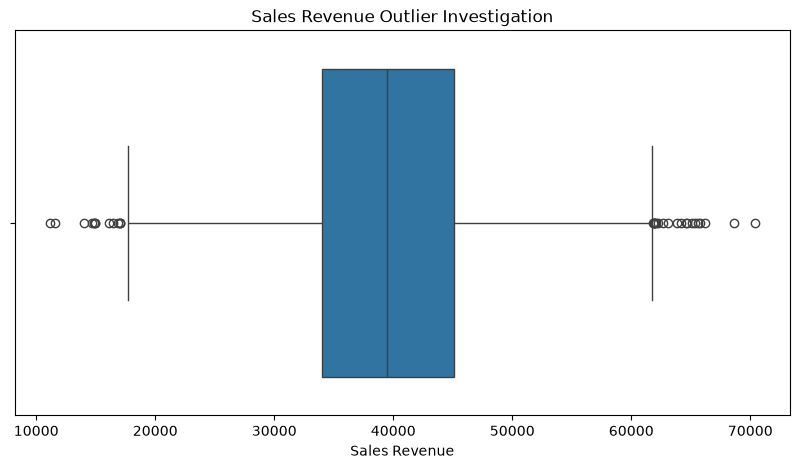

In [8]:

import matplotlib.pyplot as plt
import seaborn as sns

# Create a boxplot of sales revenue
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["SalesRevenue"])

plt.title("Sales Revenue Outlier Investigation")
plt.xlabel("Sales Revenue")

plt.show()


In [9]:

import numpy as np

# Feature 1: Revenue generated per staff hour
df["RevenuePerStaffHour"] = (
    df["SalesRevenue"] / df["StaffHours"].replace(0, np.nan)
)

# Feature 2: Revenue generated per visitor
df["RevenuePerVisitor"] = (
    df["SalesRevenue"] / df["Footfall"].replace(0, np.nan)
)

# Feature 3: Percentage change in sales
df["SalesGrowthPercentage"] = (
    (df["SalesRevenue"] - df["PreviousMonthSales"])
    / df["PreviousMonthSales"].replace(0, np.nan)
) * 100

# Display the new features
df[[
    "RevenuePerStaffHour",
    "RevenuePerVisitor",
    "SalesGrowthPercentage"
]].head()


,RevenuePerStaffHour,RevenuePerVisitor,SalesGrowthPercentage
0,120.316749,39.403192,-22.932305
1,102.798729,33.768736,2.048421
2,104.070030,43.866374,-14.735994
3,92.903571,38.836227,47.752319
4,70.139839,31.362839,-13.291936


In [10]:

features = [
    "RevenuePerStaffHour",
    "RevenuePerVisitor",
    "SalesGrowthPercentage"
]

print("Missing values:")
print(df[features].isnull().sum())

print("\nFeature summary:")
print(df[features].describe())


Missing values:
RevenuePerStaffHour      0
RevenuePerVisitor        0
SalesGrowthPercentage    0
dtype: int64

Feature summary:
       RevenuePerStaffHour  RevenuePerVisitor  SalesGrowthPercentage
count          5000.000000        5000.000000            5000.000000
mean            119.688997          37.551860             -10.573398
std              43.234232          23.348999              19.479125
min              24.015925           6.592494             -64.087280
25%              91.798708          26.390236             -23.626448
50%             113.147161          33.190521             -12.106974
75%             138.967309          42.589190               0.717647
max             734.332600         505.379900             126.956017


In [11]:

# Calculate sales performance by region
regional_sales = df.groupby("Region").agg(
    TotalRevenue=("SalesRevenue", "sum"),
    AverageRevenue=("SalesRevenue", "mean"),
    StoreRecords=("SalesRevenue", "count")
)

# Sort regions by total revenue
regional_sales = regional_sales.sort_values(
    by="TotalRevenue",
    ascending=False
)

# Display results
print(regional_sales.round(2))


        TotalRevenue  AverageRevenue  StoreRecords
Region                                            
South    51744235.17        41395.39          1250
East     49109462.45        39068.78          1257
West     48969989.45        40172.26          1219
North    48025292.43        37696.46          1274


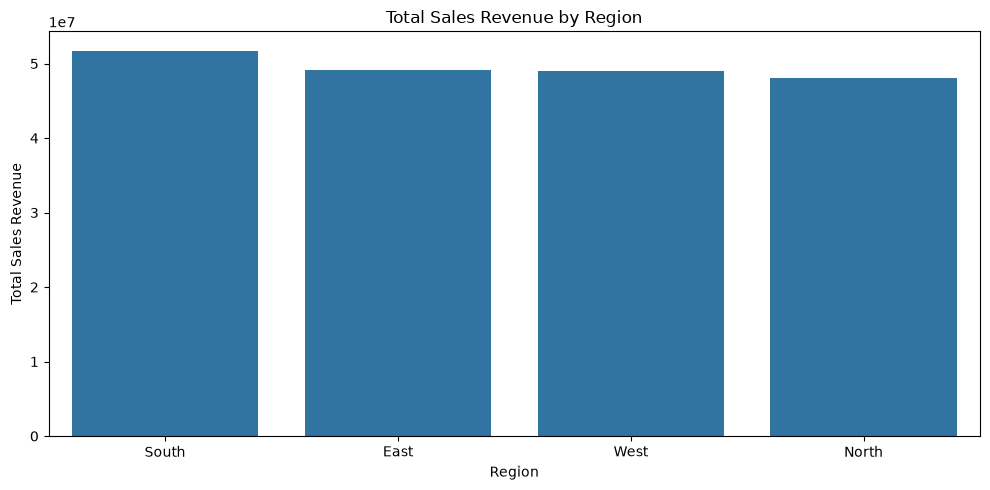

In [12]:

# Create a bar chart of total revenue by region
plt.figure(figsize=(10, 5))

sns.barplot(
    x=regional_sales.index,
    y=regional_sales["TotalRevenue"]
)

plt.title("Total Sales Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales Revenue")
plt.tight_layout()
plt.show()


In [13]:

# Group sales revenue by season
seasonal_sales = df.groupby("Season").agg(
    TotalRevenue=("SalesRevenue", "sum"),
    AverageRevenue=("SalesRevenue", "mean"),
    RecordCount=("SalesRevenue", "count")
)

# Sort by total revenue
seasonal_sales = seasonal_sales.sort_values(
    by="TotalRevenue",
    ascending=False
)

# Display the results
print(seasonal_sales.round(2))


        TotalRevenue  AverageRevenue  RecordCount
Season                                           
Winter   52441990.41        42774.87         1226
Summer   51828941.98        40778.08         1271
Spring   46933429.55        36955.46         1270
Autumn   46644617.56        37830.18         1233


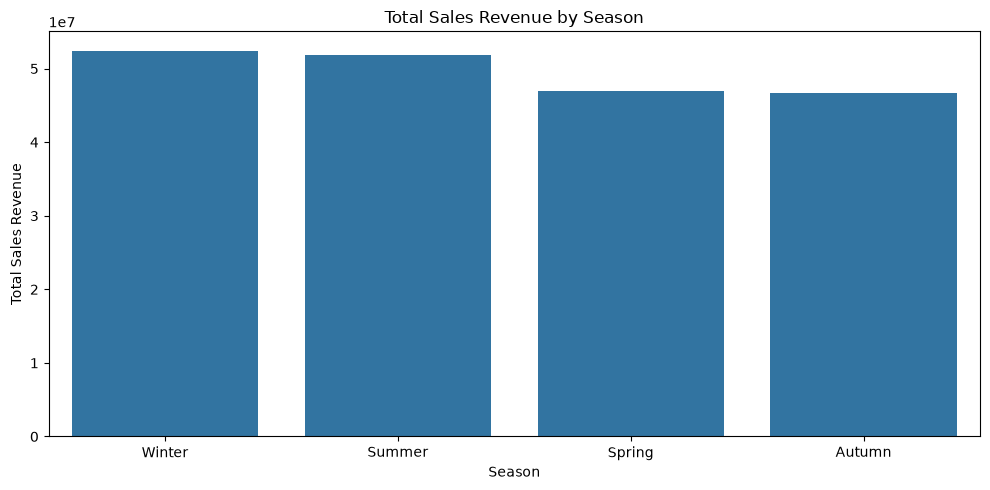

In [14]:

# Visualise seasonal revenue
plt.figure(figsize=(10, 5))

sns.barplot(
    x=seasonal_sales.index,
    y=seasonal_sales["TotalRevenue"]
)

plt.title("Total Sales Revenue by Season")
plt.xlabel("Season")
plt.ylabel("Total Sales Revenue")

plt.tight_layout()
plt.show()


In [15]:

# Group sales performance by individual store
store_performance = df.groupby("StoreID").agg(
    TotalRevenue=("SalesRevenue", "sum"),
    AverageRevenue=("SalesRevenue", "mean"),
    AverageStaffHours=("StaffHours", "mean"),
    AverageInventoryAvailability=("InventoryAvailability", "mean"),
    RecordCount=("SalesRevenue", "count")
)

# Sort stores by total revenue
store_performance = store_performance.sort_values(
    by="TotalRevenue",
    ascending=False
)

# Display the top 5 stores
print("Top 5 stores by revenue:")
print(store_performance.head().round(2))


Top 5 stores by revenue:
         TotalRevenue  AverageRevenue  AverageStaffHours  \
StoreID                                                    
1067       2540382.35        40323.53             350.16   
1071       2526175.94        40744.77             335.05   
1070       2495860.94        38997.83             368.92   
1097       2481344.29        40021.68             352.65   
1085       2474381.56        39275.90             358.32   

         AverageInventoryAvailability  RecordCount  
StoreID                                             
1067                            83.92           63  
1071                            86.46           62  
1070                            83.15           64  
1097                            84.67           62  
1085                            85.40           63  


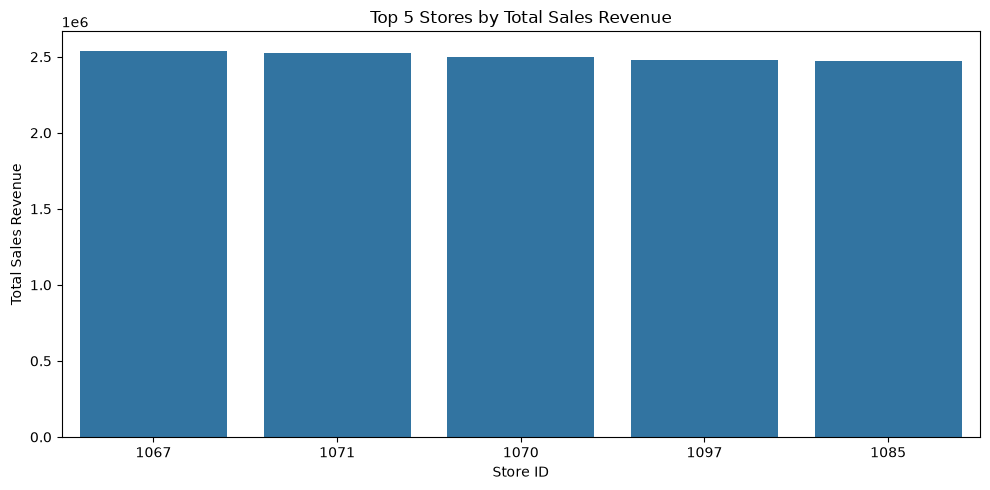

In [16]:

# Select the top 5 stores
top_5_stores = store_performance.head(5)

# Create a bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_5_stores.index.astype(str),
    y=top_5_stores["TotalRevenue"]
)

plt.title("Top 5 Stores by Total Sales Revenue")
plt.xlabel("Store ID")
plt.ylabel("Total Sales Revenue")

plt.tight_layout()
plt.show()


In [17]:

# Divide marketing spending into four groups
df["MarketingSpendGroup"] = pd.qcut(
    df["MarketingSpend"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

# Group sales by marketing spending level
marketing_performance = df.groupby(
    "MarketingSpendGroup",
    observed=True
).agg(
    AverageMarketingSpend=("MarketingSpend", "mean"),
    AverageRevenue=("SalesRevenue", "mean"),
    TotalRevenue=("SalesRevenue", "sum"),
    RecordCount=("SalesRevenue", "count")
)

# Display results
print(marketing_performance.round(2))


                     AverageMarketingSpend  AverageRevenue  TotalRevenue  \
MarketingSpendGroup                                                        
Low                                3143.79        36508.99   45636232.60   
Medium                             4624.12        38764.15   55238916.02   
High                               5445.56        40693.77   43745805.48   
Very High                          8116.47        42582.42   53228025.40   

                     RecordCount  
MarketingSpendGroup               
Low                         1250  
Medium                      1425  
High                        1075  
Very High                   1250  


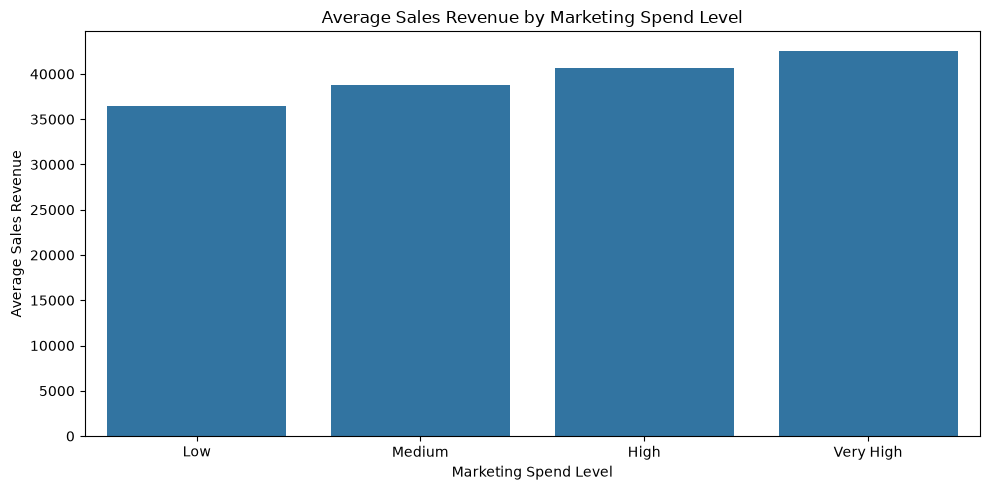

In [18]:

# Create a bar chart comparing average revenue
plt.figure(figsize=(10, 5))

sns.barplot(
    x=marketing_performance.index,
    y=marketing_performance["AverageRevenue"]
)

plt.title("Average Sales Revenue by Marketing Spend Level")
plt.xlabel("Marketing Spend Level")
plt.ylabel("Average Sales Revenue")

plt.tight_layout()
plt.show()


In [19]:

# Pivot Table 1: Average sales by region and season
pivot_region_season = pd.pivot_table(
    df,
    values="SalesRevenue",
    index="Region",
    columns="Season",
    aggfunc="mean"
)

print("Average Sales Revenue by Region and Season:")
print(pivot_region_season.round(2))


Average Sales Revenue by Region and Season:
Season    Autumn    Spring    Summer    Winter
Region                                        
East    38133.89  36028.59  40436.95  41732.68
North   35918.69  35639.47  38712.86  41163.76
South   39326.90  38760.54  42851.97  44676.99
West    38204.52  37632.14  41005.50  43424.90


In [20]:

# Pivot Table 2: Store type and regional performance
pivot_store_region = pd.pivot_table(
    df,
    values=["SalesRevenue", "InventoryAvailability"],
    index="StoreType",
    columns="Region",
    aggfunc="mean"
)

print("Store Performance by Type and Region:")
print(pivot_store_region.round(2))


Store Performance by Type and Region:
            InventoryAvailability                      SalesRevenue            \
Region                       East  North  South   West         East     North   
StoreType                                                                       
Mall                        85.00  84.85  85.22  85.20     39736.63  37303.01   
Retail Park                 84.83  85.27  84.57  84.57     38705.35  37174.91   
Town                        84.47  84.81  84.14  84.94     38776.59  38664.08   

                                 
Region          South      West  
StoreType                        
Mall         41827.41  40306.11  
Retail Park  41329.53  40034.15  
Town         41007.72  40180.90  


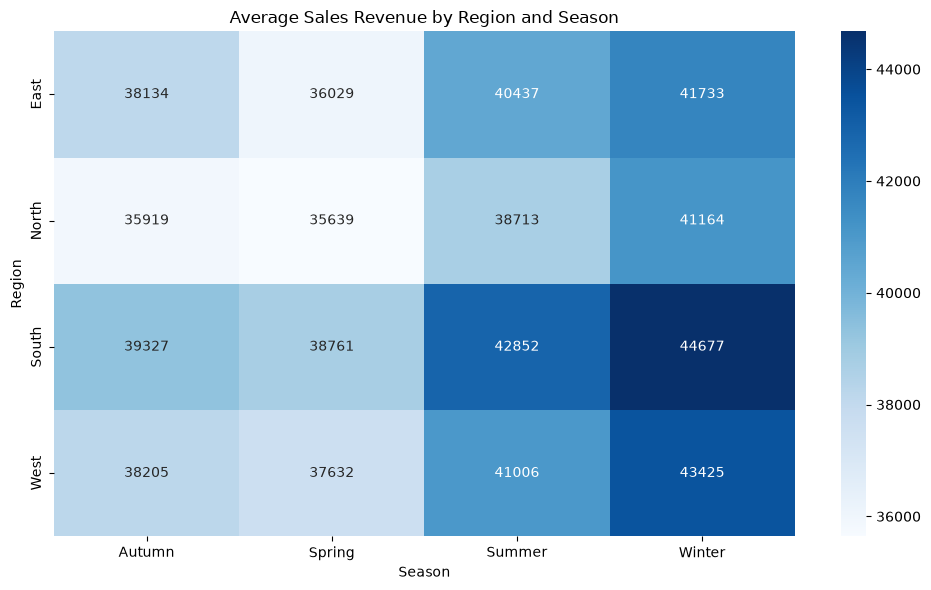

In [21]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_region_season,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Average Sales Revenue by Region and Season")
plt.xlabel("Season")
plt.ylabel("Region")

plt.tight_layout()
plt.show()


In [22]:

# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Exclude engineered features containing SalesRevenue
columns_to_exclude = [
    "RevenuePerStaffHour",
    "RevenuePerVisitor",
    "SalesGrowthPercentage",
    "StoreID"
]

numeric_df = numeric_df.drop(
    columns=columns_to_exclude,
    errors="ignore"
)

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlations with SalesRevenue
sales_correlations = correlation_matrix[
    "SalesRevenue"
].sort_values(ascending=False)

print("Correlations with Sales Revenue:")
print(sales_correlations.round(3))


Correlations with Sales Revenue:
SalesRevenue             1.000
PreviousMonthSales       0.490
MarketingSpend           0.138
InventoryAvailability    0.107
DiscountRate             0.073
Footfall                 0.020
OnlineTraffic            0.003
CompetitorDistance      -0.001
StaffHours              -0.007
CustomerSatisfaction    -0.029
Name: SalesRevenue, dtype: float64


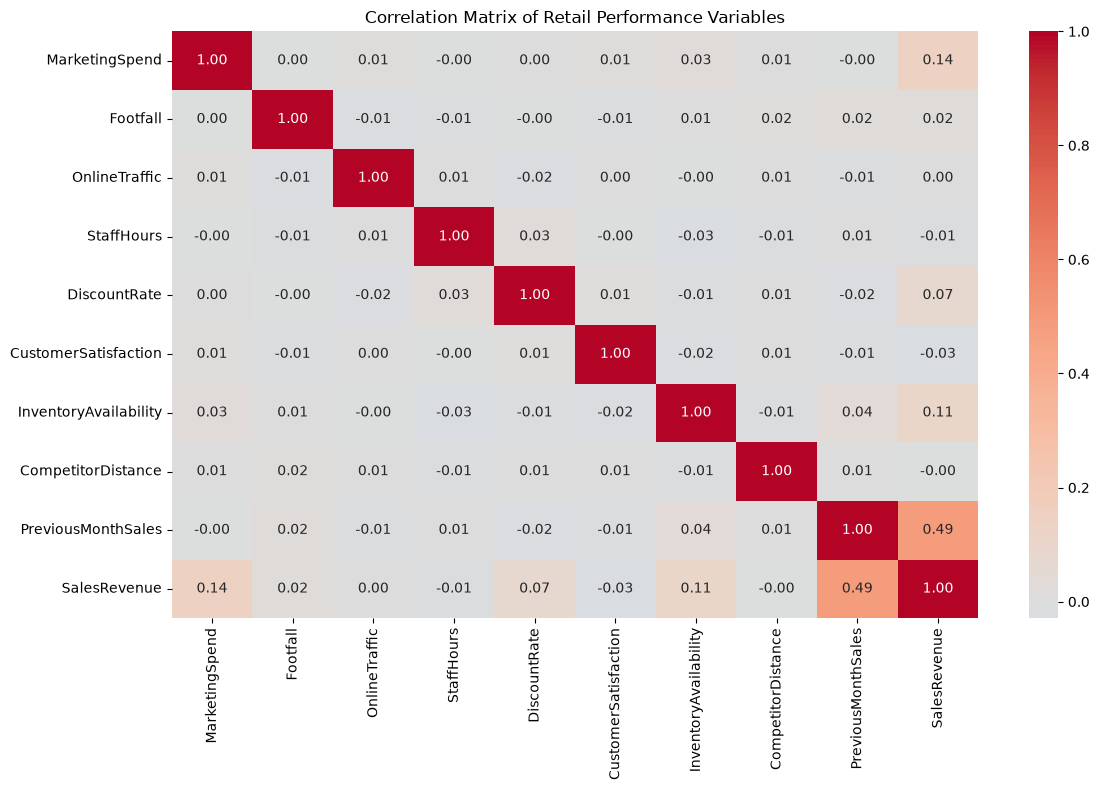

In [23]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Retail Performance Variables")

plt.tight_layout()
plt.show()


In [24]:

from sklearn.model_selection import train_test_split

# Select the variables used to predict revenue
features = [
    "MarketingSpend",
    "Footfall",
    "OnlineTraffic",
    "StaffHours",
    "DiscountRate",
    "CustomerSatisfaction",
    "InventoryAvailability",
    "CompetitorDistance",
    "PreviousMonthSales"
]

# X contains the input variables
X = df[features]

# y contains the value we want to predict
y = df["SalesRevenue"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 4000
Testing records: 1000


In [25]:

from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Create the Linear Regression model
linear_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

# Train the model using the original input columns
X_raw = pd.read_csv("Retail_outlets.csv")
X_raw = X_raw.drop_duplicates()

X_raw = X_raw.loc[df.index, features]

X_train_raw, X_test_raw = train_test_split(
    X_raw,
    test_size=0.2,
    random_state=42
)

# Train the model
linear_model.fit(X_train_raw, y_train)

# Predict sales revenue
linear_predictions = linear_model.predict(X_test_raw)

print("Linear Regression model trained successfully!")
print("First 5 predictions:")
print(linear_predictions[:5].round(2))


Linear Regression model trained successfully!
First 5 predictions:
[41406.08 47621.01 37582.23 43776.57 40680.14]


In [26]:

from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

# Create the Linear Regression model
linear_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression()
)

# Train the model using the original input columns
X_raw = pd.read_csv("Retail_outlets.csv")
X_raw = X_raw.drop_duplicates()

X_raw = X_raw.loc[df.index, features]

X_train_raw, X_test_raw = train_test_split(
    X_raw,
    test_size=0.2,
    random_state=42
)

# Train the model
linear_model.fit(X_train_raw, y_train)

# Predict sales revenue
linear_predictions = linear_model.predict(X_test_raw)

print("Linear Regression model trained successfully!")
print("First 5 predictions:")
print(linear_predictions[:5].round(2))


Linear Regression model trained successfully!
First 5 predictions:
[41406.08 47621.01 37582.23 43776.57 40680.14]


In [27]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
linear_mae = mean_absolute_error(
    y_test, linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test, linear_predictions
)

print("Linear Regression Results:")
print(f"MAE: {linear_mae:.2f}")
print(f"RMSE: {linear_rmse:.2f}")
print(f"R²: {linear_r2:.3f}")


Linear Regression Results:
MAE: 5718.98
RMSE: 7094.97
R²: 0.261


In [28]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

# Create Random Forest model
random_forest_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
)

# Train the model
random_forest_model.fit(X_train_raw, y_train)

# Make predictions
rf_predictions = random_forest_model.predict(X_test_raw)

print("Random Forest model trained successfully!")

print("First 5 predictions:")
print(rf_predictions[:5].round(2))


Random Forest model trained successfully!
First 5 predictions:
[40124.83 42792.95 39899.59 41395.25 39123.82]


In [29]:

# Calculate Random Forest evaluation metrics
rf_mae = mean_absolute_error(
    y_test, rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(
    y_test, rf_predictions
)

print("Random Forest Results:")
print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²: {rf_r2:.3f}")


Random Forest Results:
MAE: 5540.16
RMSE: 6915.26
R²: 0.298


In [30]:

# Create model comparison table
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [linear_mae, rf_mae],
    "RMSE": [linear_rmse, rf_rmse],
    "R2": [linear_r2, rf_r2]
})

print(model_comparison.round(3))


               Model       MAE      RMSE     R2
0  Linear Regression  5718.983  7094.966  0.261
1      Random Forest  5540.162  6915.256  0.298


In [31]:

# Extract the trained Random Forest model
rf_model = random_forest_model.named_steps[
    "randomforestregressor"
]

# Get feature importance scores
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(feature_importance.round(4))


Random Forest Feature Importance:
                 Feature  Importance
8     PreviousMonthSales      0.3260
0         MarketingSpend      0.1711
4           DiscountRate      0.0821
6  InventoryAvailability      0.0765
3             StaffHours      0.0720
1               Footfall      0.0701
7     CompetitorDistance      0.0680
2          OnlineTraffic      0.0678
5   CustomerSatisfaction      0.0663


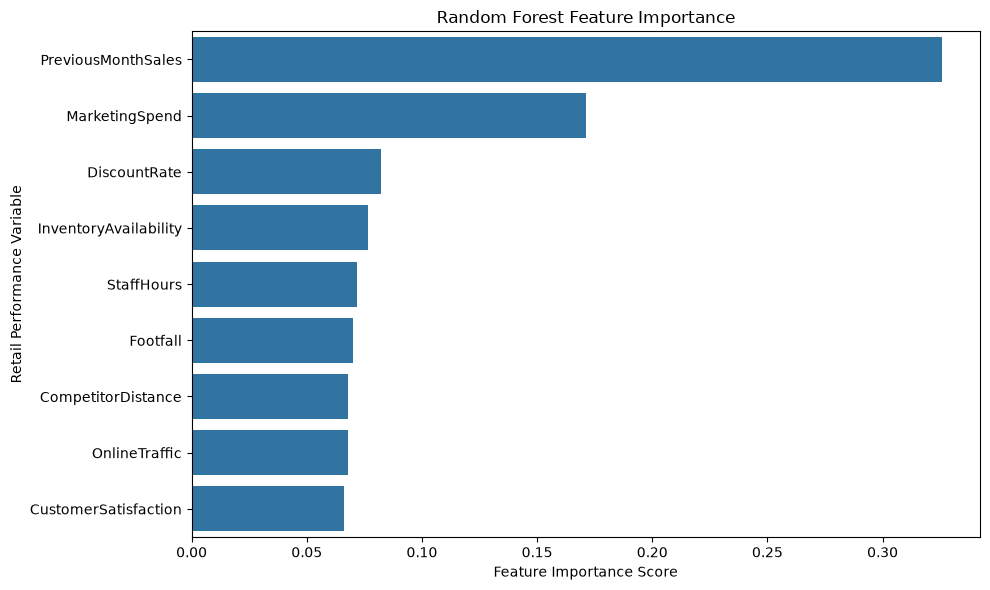

In [32]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Feature Importance Score")
plt.ylabel("Retail Performance Variable")

plt.tight_layout()
plt.show()


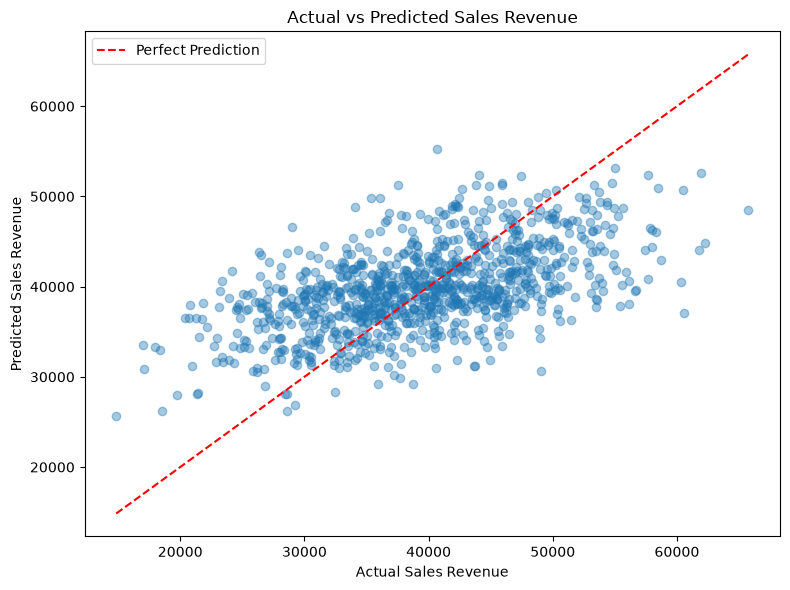

In [33]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.4
)

# Perfect prediction reference line
minimum = min(y_test.min(), rf_predictions.min())
maximum = max(y_test.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Sales Revenue")
plt.xlabel("Actual Sales Revenue")
plt.ylabel("Predicted Sales Revenue")
plt.legend()

plt.tight_layout()
plt.show()



In [34]:

# Extract the trained Random Forest model
rf_model = random_forest_model.named_steps[
    "randomforestregressor"
]

# Get feature importance scores
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

# Sort features from most important to least important
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Random Forest Feature Importance:")
print(feature_importance.round(4))


Random Forest Feature Importance:
                 Feature  Importance
8     PreviousMonthSales      0.3260
0         MarketingSpend      0.1711
4           DiscountRate      0.0821
6  InventoryAvailability      0.0765
3             StaffHours      0.0720
1               Footfall      0.0701
7     CompetitorDistance      0.0680
2          OnlineTraffic      0.0678
5   CustomerSatisfaction      0.0663


In [35]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone

# Load original data and remove duplicates
validation_df = pd.read_csv("Retail_outlets.csv")
validation_df = validation_df.drop_duplicates()

# Separate inputs, target and store identifiers
X_group = validation_df[features]
y_group = validation_df["SalesRevenue"]
store_groups = validation_df["StoreID"]

# Split by store rather than individual rows
group_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    group_split.split(X_group, y_group, groups=store_groups)
)

X_train_group = X_group.iloc[train_idx]
X_test_group = X_group.iloc[test_idx]

y_train_group = y_group.iloc[train_idx]
y_test_group = y_group.iloc[test_idx]

# Create fresh copies of the models
linear_group_model = clone(linear_model)
rf_group_model = clone(random_forest_model)

# Train on the new training set
linear_group_model.fit(X_train_group, y_train_group)
rf_group_model.fit(X_train_group, y_train_group)

# Generate predictions
linear_group_predictions = linear_group_model.predict(X_test_group)
rf_group_predictions = rf_group_model.predict(X_test_group)

print("Training records:", len(train_idx))
print("Testing records:", len(test_idx))
print("Unique test stores:", store_groups.iloc[test_idx].nunique())


Training records: 4009
Testing records: 991
Unique test stores: 20


In [36]:

group_results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test_group, linear_group_predictions),
        mean_absolute_error(y_test_group, rf_group_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_group, linear_group_predictions)),
        np.sqrt(mean_squared_error(y_test_group, rf_group_predictions))
    ],
    "R2": [
        r2_score(y_test_group, linear_group_predictions),
        r2_score(y_test_group, rf_group_predictions)
    ]
})

print(group_results.round(3))


               Model       MAE      RMSE     R2
0  Linear Regression  5589.639  6894.689  0.246
1      Random Forest  5501.945  6793.838  0.268


In [37]:
staff_by_region = df.groupby("Region").agg(
    TotalStaffHours=("StaffHours", "sum"),
    AverageStaffHours=("StaffHours", "mean"),
    TotalRevenue=("SalesRevenue", "sum")
)

staff_by_region["RevenuePerStaffHour"] = (
    staff_by_region["TotalRevenue"] /
    staff_by_region["TotalStaffHours"]
)

display(staff_by_region.round(2))

,TotalStaffHours,AverageStaffHours,TotalRevenue,RevenuePerStaffHour
Region,,,,
East,443984.57,353.21,49109462.45,110.61
North,445978.15,350.06,48025292.43,107.69
South,438383.54,350.71,51744235.17,118.03
West,429527.10,352.36,48969989.45,114.01


In [40]:
inventory_by_region = df.groupby("Region").agg(
    AverageInventoryAvailability=("InventoryAvailability", "mean"),
    AverageSalesRevenue=("SalesRevenue", "mean")
)

display(inventory_by_region.round(2))

,AverageInventoryAvailability,AverageSalesRevenue
Region,,
East,84.77,39068.78
North,84.98,37696.46
South,84.65,41395.39
West,84.90,40172.26


In [39]:
%whos DataFrame

Variable                Type         Data/Info
----------------------------------------------
X                       DataFrame    Shape: (5000, 9)
X_group                 DataFrame    Shape: (5000, 9)
X_raw                   DataFrame    Shape: (5000, 9)
X_test                  DataFrame    Shape: (1000, 9)
X_test_group            DataFrame    Shape: (991, 9)
X_test_raw              DataFrame    Shape: (1000, 9)
X_train                 DataFrame    Shape: (4000, 9)
X_train_group           DataFrame    Shape: (4009, 9)
X_train_raw             DataFrame    Shape: (4000, 9)
correlation_matrix      DataFrame    Shape: (10, 10)
df                      DataFrame    Shape: (5000, 18)
feature_importance      DataFrame    Shape: (9, 2)
group_results           DataFrame    Shape: (2, 4)
marketing_performance   DataFrame    Shape: (4, 4)
missing_summary         DataFrame    Shape: (14, 2)
model_comparison        DataFrame    Shape: (2, 4)
numeric_df              DataFrame    Shape: (5000, 10)
ou

In [41]:
regional_comparison = df.groupby("Region").agg(
    AverageRevenue=("SalesRevenue", "mean"),
    AverageFootfall=("Footfall", "mean"),
    AverageStaffHours=("StaffHours", "mean"),
    AverageMarketingSpend=("MarketingSpend", "mean"),
    AverageCustomerSatisfaction=("CustomerSatisfaction", "mean"),
    AverageRevenuePerStaffHour=("RevenuePerStaffHour", "mean")
)

display(regional_comparison.round(2))

,AverageRevenue,AverageFootfall,AverageStaffHours,AverageMarketingSpend,AverageCustomerSatisfaction,AverageRevenuePerStaffHour
Region,,,,,,
East,39068.78,1174.83,353.21,5445.55,75.00,117.91
North,37696.46,1202.13,350.06,5168.77,75.21,114.93
South,41395.39,1198.01,350.71,5226.67,75.23,125.47
West,40172.26,1191.61,352.36,5377.57,74.92,120.57


In [42]:
customer_behaviour = df.groupby("Region").agg(
    TotalRevenue=("SalesRevenue", "sum"),
    TotalFootfall=("Footfall", "sum")
)

customer_behaviour["RevenuePerVisitor"] = (
    customer_behaviour["TotalRevenue"] /
    customer_behaviour["TotalFootfall"]
)

display(customer_behaviour.round(2))

,TotalRevenue,TotalFootfall,RevenuePerVisitor
Region,,,
East,49109462.45,1476764.83,33.25
North,48025292.43,1531508.97,31.36
South,51744235.17,1497507.10,34.55
West,48969989.45,1452572.50,33.71


In [43]:
competition_by_region = df.groupby("Region").agg(
    AverageCompetitorDistance=("CompetitorDistance", "mean"),
    AverageRevenue=("SalesRevenue", "mean")
)

display(competition_by_region.round(2))

,AverageCompetitorDistance,AverageRevenue
Region,,
East,10.30,39068.78
North,10.39,37696.46
South,10.03,41395.39
West,10.15,40172.26


In [44]:
discount_by_region = df.groupby("Region").agg(
    AverageDiscount=("DiscountRate", "mean"),
    AverageRevenue=("SalesRevenue", "mean")
)

display(discount_by_region.round(2))

,AverageDiscount,AverageRevenue
Region,,
East,20.27,39068.78
North,20.24,37696.46
South,20.10,41395.39
West,20.39,40172.26
